# tertiary-adjunct 00 · Signals and their history (development years)

The protocol ([`configs/protocol.toml`](../configs/protocol.toml), README "Protocol") was committed
before any of this was run. This notebook only looks at **2012-2019**: the information
coefficients (ICs) of the holdout years are not shown, because composite C3 learns its weights
from them.

- **Panel**: 17 point-in-time signals in 7 groups, on every signal date (the last trading day of
  each month and the last on or before the 15th), for the 1,000 largest companies on that date.
- **IC**: the monthly rank correlation between a signal (oriented so higher is better) and the
  return from that month end's next close to the next month end's next close.

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from tertiary_adjunct import Study, signals

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(16)
st = Study()
P = st.p
DEV_END = pl.lit(P["periods"]["dev_end"]).str.to_date()
groups = {s: g for g, ss in P["signals"].items() for s in ss}
panel = st.panel().filter(pl.col("date") <= DEV_END)
ics = st.ics().filter(pl.col("next_date") <= DEV_END)
print(f"{panel.height:,} rows, {panel['date'].n_unique()} signal dates, {panel['date'].min()} to {panel['date'].max()}")

192,000 rows, 192 signal dates, 2012-01-13 to 2019-12-31


## 1 · Coverage

The share of the universe that has each signal, by year. Fundamentals fill in during 2012 as XBRL filings accumulate.

In [2]:
cov = (panel.group_by(pl.col("date").dt.year().alias("year"))
       .agg([pl.col(s).is_not_null().mean().round(2).alias(s) for s in signals(P)]).sort("year"))
cov.unpivot(index="year", variable_name="signal").pivot(on="year", index="signal", values="value")

signal,2012,2013,2014,2015,2016,2017,2018,2019
str,f64,f64,f64,f64,f64,f64,f64,f64
"""earnings_yield""",0.93,0.95,0.95,0.95,0.96,0.96,0.91,0.89
"""book_to_market""",0.95,0.95,0.95,0.95,0.96,0.96,0.9,0.89
"""fcf_yield""",0.83,0.85,0.86,0.88,0.89,0.88,0.83,0.81
"""ebitda_to_ev""",0.62,0.64,0.64,0.65,0.65,0.65,0.63,0.62
"""roe""",0.92,0.94,0.93,0.93,0.93,0.93,0.94,0.94
"""gross_profitability""",0.42,0.43,0.43,0.43,0.43,0.42,0.43,0.44
"""cash_roa""",0.96,0.97,0.97,0.98,0.98,0.98,0.98,0.98
"""accruals""",0.95,0.97,0.97,0.97,0.98,0.98,0.98,0.98
"""momentum_12_1""",0.98,0.98,0.97,0.98,0.99,0.98,0.98,0.98


## 2 · Information coefficients, 2012-2019

Mean monthly rank IC, its standard deviation, the IC information ratio (mean / sd, monthly), the t-statistic and the share of positive months.

In [3]:
tab = (ics.group_by("signal").agg(pl.len().alias("months"), pl.col("ic").mean().alias("mean_ic"),
                                  pl.col("ic").std().alias("ic_sd"), (pl.col("ic") > 0).mean().alias("positive"))
       .with_columns((pl.col("mean_ic") / pl.col("ic_sd")).alias("ic_ir"),
                     (pl.col("mean_ic") / pl.col("ic_sd") * pl.col("months").sqrt()).alias("t"),
                     pl.col("signal").replace_strict(groups).alias("group"))
       .select("group", "signal", "months", "mean_ic", "ic_sd", "ic_ir", "t", "positive")
       .sort("group", "signal").with_columns(pl.col(pl.Float64).round(3)))
tab

group,signal,months,mean_ic,ic_sd,ic_ir,t,positive
str,str,u32,f64,f64,f64,f64,f64
"""investment""","""asset_growth""",95,-0.001,0.08,-0.015,-0.142,0.505
"""investment""","""share_issuance""",95,0.021,0.1,0.207,2.02,0.589
"""leverage""","""debt_to_equity""",95,-0.009,0.073,-0.124,-1.211,0.453
"""leverage""","""interest_coverage""",95,0.012,0.095,0.13,1.27,0.589
"""low_risk""","""high_52w""",95,0.012,0.181,0.066,0.647,0.505
"""low_risk""","""volatility_3m""",95,0.018,0.191,0.092,0.897,0.537
"""momentum""","""momentum_12_1""",95,0.016,0.166,0.096,0.937,0.516
"""quality""","""accruals""",95,0.001,0.077,0.016,0.151,0.537
"""quality""","""cash_roa""",95,0.013,0.09,0.149,1.454,0.516


In [4]:
by_group = (ics.with_columns(pl.col("signal").replace_strict(groups).alias("group"))
            .group_by("group", "date").agg(pl.col("ic").mean())
            .group_by("group").agg(pl.col("ic").mean().alias("mean_ic"), (pl.col("ic").mean() / pl.col("ic").std()).alias("ic_ir"))
            .sort("ic_ir", descending=True).with_columns(pl.col(pl.Float64).round(3)))
by_group

group,mean_ic,ic_ir
str,f64,f64
"""quality""",0.011,0.166
"""investment""",0.01,0.127
"""momentum""",0.016,0.096
"""short""",0.006,0.085
"""low_risk""",0.015,0.085
"""leverage""",0.002,0.022
"""value""",-0.001,-0.014


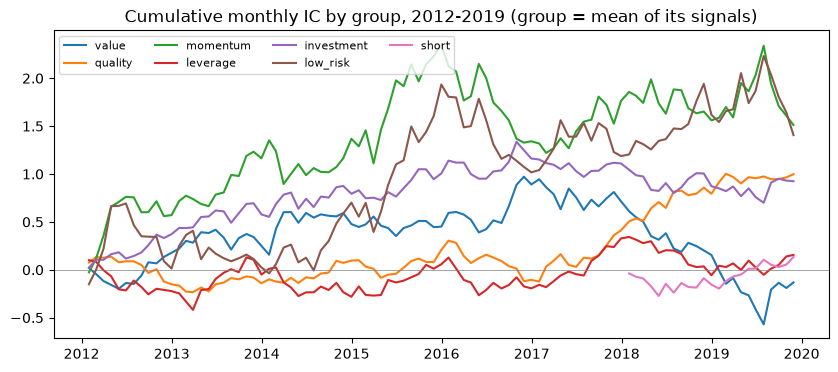

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for g in P["signals"]:
    s = (ics.with_columns(pl.col("signal").replace_strict(groups).alias("group")).filter(pl.col("group") == g)
         .group_by("date").agg(pl.col("ic").mean()).sort("date"))
    ax.plot(s["date"], s["ic"].cum_sum(), label=g)
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Cumulative monthly IC by group, 2012-2019 (group = mean of its signals)")
ax.legend(ncol=4, fontsize=8)
plt.show()

## 3 · How the groups move together

Correlation of the groups' monthly ICs: groups whose good and bad months offset are what make a combination worth having.

In [6]:
gm = (ics.with_columns(pl.col("signal").replace_strict(groups).alias("group"))
      .group_by("group", "date").agg(pl.col("ic").mean()).pivot(on="group", index="date", values="ic").sort("date"))
# Pairwise (short interest starts in 2018, so its column is shorter).
gm.drop("date").to_pandas().corr(min_periods=12).round(2)

,quality,investment,value,leverage,low_risk,momentum,short
quality,1.00,0.06,-0.31,0.39,0.20,0.19,-0.27
investment,0.06,1.00,0.73,0.41,-0.05,-0.42,0.27
value,-0.31,0.73,1.00,0.18,-0.32,-0.64,0.02
leverage,0.39,0.41,0.18,1.00,-0.23,-0.01,0.18
low_risk,0.20,-0.05,-0.32,-0.23,1.00,0.62,0.16
momentum,0.19,-0.42,-0.64,-0.01,0.62,1.00,0.12
short,-0.27,0.27,0.02,0.18,0.16,0.12,1.00


## 4 · C3's walk-forward weights

C3 weights each signal by its trailing 36 month-end ICs (mean / sd, negatives at 0), shrunk halfway to equal weights, using only ICs whose month had passed. Before 24 months of ICs it is equal weighted (all of 2012-2013).

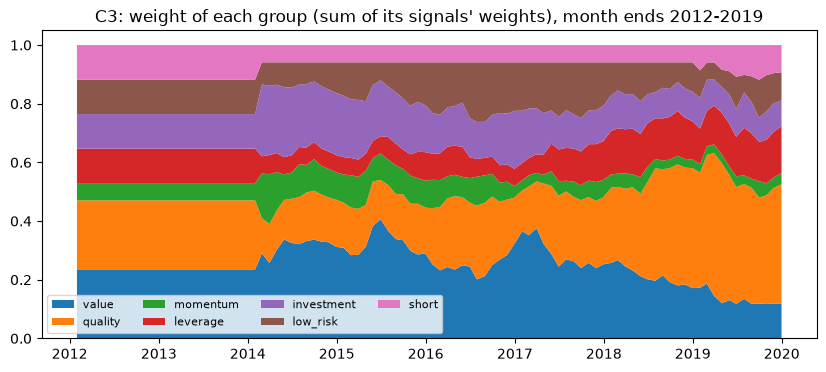

date,signal,weight,known
date,str,f64,i64
2019-12-31,"""roe""",0.156,36
2019-12-31,"""interest_coverage""",0.13,36
2019-12-31,"""cash_roa""",0.115,36
2019-12-31,"""gross_profitability""",0.091,36
2019-12-31,"""si_pct_float""",0.064,36
2019-12-31,"""share_issuance""",0.058,36
2019-12-31,"""volatility_3m""",0.057,36
2019-12-31,"""accruals""",0.046,36
2019-12-31,"""momentum_12_1""",0.039,36


In [7]:
from tertiary_adjunct import walk_forward_weights

spec = P["composites"]["C3"]
me = st.month_ends(P["periods"]["signals_from"], P["periods"]["dev_end"])
ww = walk_forward_weights(st.ics(), me, signals(P, spec["groups"]), spec["window_months"], spec["min_months"], spec["shrink"])
wg = (ww.with_columns(pl.col("signal").replace_strict(groups).alias("group"))
      .group_by("date", "group").agg(pl.col("weight").sum()).pivot(on="group", index="date", values="weight").sort("date"))
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(wg["date"], *[wg[g] for g in P["signals"]], labels=list(P["signals"]))
ax.set_title("C3: weight of each group (sum of its signals' weights), month ends 2012-2019")
ax.legend(ncol=4, fontsize=8, loc="lower left")
plt.show()
ww.filter(pl.col("date") == me[-1]).sort("weight", descending=True).with_columns(pl.col("weight").round(3))

## 5 · The three scores

Average cross-sectional rank correlation between the composites on each signal date.

In [8]:
sc = st.scored().filter(pl.col("date") <= DEV_END)
pairs = [("C1", "C2"), ("C1", "C3"), ("C2", "C3")]
pl.DataFrame([{"pair": f"{a}-{b}", "mean_rank_corr": sc.drop_nulls([a, b]).group_by("date")
               .agg(pl.corr(a, b, method="spearman").alias("c"))["c"].mean()} for a, b in pairs]).with_columns(pl.col("mean_rank_corr").round(3))

pair,mean_rank_corr
str,f64
"""C1-C2""",0.764
"""C1-C3""",0.752
"""C2-C3""",0.868


## 6 · What this shows

- **The signals were weak on their own in 2012-2019.** Only three have a t-statistic near 2: `fcf_yield`, `roe` and `share_issuance`, each with a monthly rank IC of about 0.02.
- **Value lost.** Book-to-market had a negative IC (t = -1.6), as did EBITDA/EV. This is the value drawdown of the 2010s.
- **Group ICs.** Momentum and low risk have positive but noisy ICs (sd 0.17-0.19), and they move together (0.62). Both move against value (momentum -0.64). Value and investment move together (0.73), so equal group weights give that pair a double vote.
- **Short interest** has only 23 months of ICs before 2020.
- **C3 by the end of 2019** leans on quality and coverage: `roe` 16%, `interest_coverage` 13%, `cash_roa` 12%. Every signal with a negative trailing IC sits at the shrink floor (0.5 / 17 = 2.9%).
- **The three scores rank names alike** (rank correlation 0.75-0.87), so they are close cousins, and the backtests should not be expected to differ much.